# Online Gaming Behaviour Using Machine Learning

In [1]:
import warnings
warnings.filterwarnings("ignore")

# Importing Libraries

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

In [3]:
df = pd.read_csv("online_gaming_behavior_dataset.csv")

In [4]:
df.shape

(40034, 13)

In [5]:
df.head()

,PlayerID,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,EngagementLevel
0,9000,43,Male,Other,Strategy,16.271119,0,Medium,6,108,79,25,Medium
1,9001,29,Female,USA,Strategy,5.525961,0,Medium,5,144,11,10,Medium
2,9002,22,Female,USA,Sports,8.223755,0,Easy,16,142,35,41,High
3,9003,35,Male,USA,Action,5.265351,1,Easy,9,85,57,47,Medium
4,9004,33,Male,Europe,Action,15.531945,0,Medium,2,131,95,37,Medium


In [6]:
df.tail()

,PlayerID,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,EngagementLevel
40029,49029,32,Male,USA,Strategy,20.619662,0,Easy,4,75,85,14,Medium
40030,49030,44,Female,Other,Simulation,13.539280,0,Hard,19,114,71,27,High
40031,49031,15,Female,USA,RPG,0.240057,1,Easy,10,176,29,1,High
40032,49032,34,Male,USA,Sports,14.017818,1,Medium,3,128,70,10,Medium
40033,49033,19,Male,USA,Sports,10.083804,0,Easy,13,84,72,39,Medium


In [7]:
df.columns

Index(['PlayerID', 'Age', 'Gender', 'Location', 'GameGenre', 'PlayTimeHours',
       'InGamePurchases', 'GameDifficulty', 'SessionsPerWeek',
       'AvgSessionDurationMinutes', 'PlayerLevel', 'AchievementsUnlocked',
       'EngagementLevel'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40034 entries, 0 to 40033
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PlayerID                   40034 non-null  int64  
 1   Age                        40034 non-null  int64  
 2   Gender                     40034 non-null  object 
 3   Location                   40034 non-null  object 
 4   GameGenre                  40034 non-null  object 
 5   PlayTimeHours              40034 non-null  float64
 6   InGamePurchases            40034 non-null  int64  
 7   GameDifficulty             40034 non-null  object 
 8   SessionsPerWeek            40034 non-null  int64  
 9   AvgSessionDurationMinutes  40034 non-null  int64  
 10  PlayerLevel                40034 non-null  int64  
 11  AchievementsUnlocked       40034 non-null  int64  
 12  EngagementLevel            40034 non-null  object 
dtypes: float64(1), int64(7), object(5)
memory usag

In [9]:
df.describe()

,PlayerID,Age,PlayTimeHours,InGamePurchases,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked
count,40034.000000,40034.000000,40034.000000,40034.000000,40034.000000,40034.000000,40034.000000,40034.000000
mean,29016.500000,31.992531,12.024365,0.200854,9.471774,94.792252,49.655568,24.526477
std,11556.964675,10.043227,6.914638,0.400644,5.763667,49.011375,28.588379,14.430726
min,9000.000000,15.000000,0.000115,0.000000,0.000000,10.000000,1.000000,0.000000
25%,19008.250000,23.000000,6.067501,0.000000,4.000000,52.000000,25.000000,12.000000
50%,29016.500000,32.000000,12.008002,0.000000,9.000000,95.000000,49.000000,25.000000
75%,39024.750000,41.000000,17.963831,0.000000,14.000000,137.000000,74.000000,37.000000
max,49033.000000,49.000000,23.999592,1.000000,19.000000,179.000000,99.000000,49.000000


In [10]:
df.isnull().sum()

PlayerID                     0
Age                          0
Gender                       0
Location                     0
GameGenre                    0
PlayTimeHours                0
InGamePurchases              0
GameDifficulty               0
SessionsPerWeek              0
AvgSessionDurationMinutes    0
PlayerLevel                  0
AchievementsUnlocked         0
EngagementLevel              0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df = df.drop_duplicates()

In [13]:
df.head(10)

,PlayerID,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,EngagementLevel
0,9000,43,Male,Other,Strategy,16.271119,0,Medium,6,108,79,25,Medium
1,9001,29,Female,USA,Strategy,5.525961,0,Medium,5,144,11,10,Medium
2,9002,22,Female,USA,Sports,8.223755,0,Easy,16,142,35,41,High
3,9003,35,Male,USA,Action,5.265351,1,Easy,9,85,57,47,Medium
4,9004,33,Male,Europe,Action,15.531945,0,Medium,2,131,95,37,Medium
5,9005,37,Male,Europe,RPG,20.561855,0,Easy,2,81,74,22,Low
6,9006,25,Male,USA,Action,9.752716,0,Hard,1,50,13,2,Low
7,9007,25,Female,Asia,RPG,4.401729,0,Medium,10,48,27,23,Medium
8,9008,38,Female,Europe,Simulation,18.152733,0,Easy,5,101,23,41,Medium
9,9009,38,Female,Other,Sports,23.942772,0,Easy,13,95,99,36,High


In [14]:
X = df.drop("EngagementLevel", axis=1)

In [15]:
y = df["EngagementLevel"]

In [16]:
X = pd.get_dummies(X, drop_first=True)

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [20]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [21]:
import os

print(os.getcwd())

C:\Users\ritik


# Machine Learning Algorithms

# Logistic Regression

In [22]:
from sklearn.linear_model import LogisticRegression

In [23]:
lr = LogisticRegression()

In [24]:
lr.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [25]:
y_pred_lr = lr.predict(X_test)
y_pred_lr

array(['Medium', 'Medium', 'Medium', ..., 'Medium', 'Medium', 'Medium'],
      shape=(8007,), dtype=object)

In [26]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [27]:
acc = accuracy_score(y_test, y_pred_lr)
print("Accuracy:", acc)

Accuracy: 0.8212813787935557


In [28]:
print("Precision :",precision_score(y_test,y_pred_lr,average='weighted'))

Precision : 0.8233494653770085


In [29]:
print("Recall :",recall_score(y_test,y_pred_lr,average='weighted'))

Recall : 0.8212813787935557


In [30]:
print("F1 Score :",f1_score(y_test,y_pred_lr,average='weighted'))

F1 Score : 0.8198789997553453


In [31]:
cm = confusion_matrix(y_test, y_pred_lr)
print(cm)

[[1672   58  305]
 [  61 1466  566]
 [ 146  295 3438]]


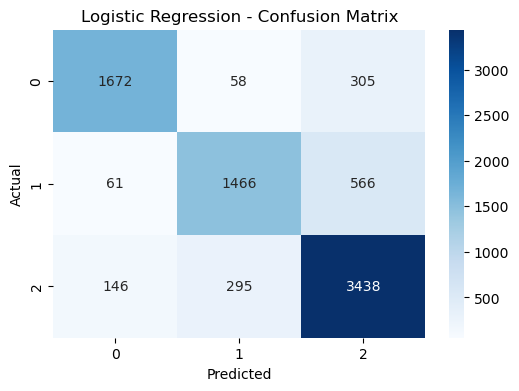

In [32]:
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### Observation 

Logistic Regression successfully classified the player engagement levels with good overall performance. 
It produced reliable predictions and served as an effective baseline model. However, more advanced algorithms may achieve higher accuracy on complex datasets.

# Decision Tree

In [33]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

In [34]:
dt = DecisionTreeClassifier(random_state=42)

In [35]:
dt.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [36]:
y_pred_dt = dt.predict(X_test)
y_pred_dt

array(['Low', 'Medium', 'Low', ..., 'Medium', 'Medium', 'Medium'],
      shape=(8007,), dtype=object)

In [37]:
acc = accuracy_score(y_test, y_pred_dt)
print("Accuracy:", acc)

Accuracy: 0.8292743849132009


In [38]:
print("Precision :", precision_score(y_test, y_pred_dt, average='weighted'))

Precision : 0.8298850717749399


In [39]:
print("Recall :", recall_score(y_test, y_pred_dt, average='weighted'))

Recall : 0.8292743849132009


In [40]:
print("F1 Score :", f1_score(y_test, y_pred_dt, average='weighted'))


F1 Score : 0.8295112318725663


In [41]:
cm = confusion_matrix(y_test, y_pred_dt)
print(cm)

[[1668  128  239]
 [ 143 1677  273]
 [ 266  318 3295]]


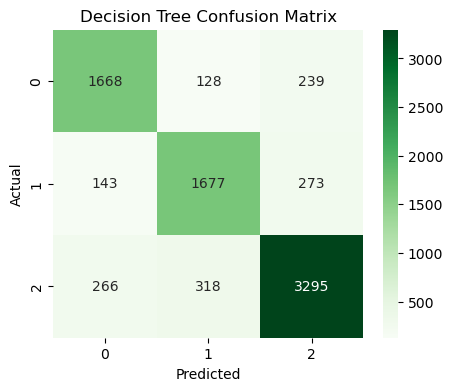

In [42]:
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens")
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [43]:
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

        High       0.80      0.82      0.81      2035
         Low       0.79      0.80      0.80      2093
      Medium       0.87      0.85      0.86      3879

    accuracy                           0.83      8007
   macro avg       0.82      0.82      0.82      8007
weighted avg       0.83      0.83      0.83      8007



### Observation

The model's performance was evaluated using Accuracy, Precision, Recall, F1-Score, and Confusion Matrix. 
Decision Trees can capture complex relationships but may overfit if not properly controlled.

<br><br><br><br>

# Random Forest Classifier

In [44]:
from sklearn.ensemble import RandomForestClassifier

In [45]:
rf = RandomForestClassifier(
    random_state=42,
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=5,
    n_jobs=-1
)

In [46]:
rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,5
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [47]:
y_pred_rf = rf.predict(X_test)
y_pred_rf

array(['Medium', 'Medium', 'Low', ..., 'Medium', 'Medium', 'Medium'],
      shape=(8007,), dtype=object)

In [48]:
acc = accuracy_score(y_test, y_pred_rf)
print("Accuracy:", acc)

Accuracy: 0.8729861371300113


In [49]:
print("Precision :", precision_score(y_test, y_pred_rf, average='weighted'))

Precision : 0.8769582012954993


In [50]:
print("Recall :", recall_score(y_test, y_pred_rf, average='weighted'))

Recall : 0.8729861371300113


In [51]:
print("F1 Score :", f1_score(y_test, y_pred_rf, average='weighted'))

F1 Score : 0.8718961152286284


In [52]:
cm_rf = confusion_matrix(y_test, y_pred_rf)
print(cm_rf)

[[1632   64  339]
 [  55 1691  347]
 [ 118   94 3667]]


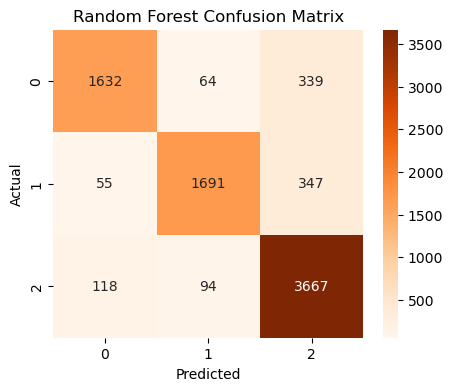

In [53]:
plt.figure(figsize=(5,4))
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Oranges")
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
print(classification_report(y_test, y_pred_rf, zero_division=0))

              precision    recall  f1-score   support

        High       0.90      0.80      0.85      2035
         Low       0.91      0.81      0.86      2093
      Medium       0.84      0.95      0.89      3879

    accuracy                           0.87      8007
   macro avg       0.89      0.85      0.87      8007
weighted avg       0.88      0.87      0.87      8007



## Observation

Random Forest achieved high accuracy but failed to detect any fraudulent transactions, resulting in zero Recall and F1-Score.

<br><br><br><br>

# KNN Model

In [53]:
from sklearn.decomposition import PCA

In [54]:
pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

In [55]:
from sklearn.neighbors import KNeighborsClassifier

In [56]:
for k in [3, 5, 7, 9]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_pca, y_train)

    prediction = knn.predict(X_test_pca)
    accuracy = accuracy_score(y_test, prediction)
    print(f"K = {k}, Accuracy = {accuracy:.4f}")

K = 3, Accuracy = 0.6648
K = 5, Accuracy = 0.6803
K = 7, Accuracy = 0.6979
K = 9, Accuracy = 0.7089


In [57]:
best_knn = KNeighborsClassifier(n_neighbors=9)
best_knn.fit(X_train_pca, y_train)
y_pred_knn = best_knn.predict(X_test_pca)

In [58]:
acc = accuracy_score(y_test, y_pred_knn)
print("Accuracy:", acc)

Accuracy: 0.7088797302360434


In [59]:
print("Precision :", precision_score(y_test, y_pred_knn, average='weighted'))

Precision : 0.7166253986835806


In [60]:
print("Recall :", recall_score(y_test, y_pred_knn, average='weighted'))

Recall : 0.7088797302360434


In [61]:
print("F1 Score :", f1_score(y_test, y_pred_knn, average='weighted'))

F1 Score : 0.7029543530783314


In [62]:
cm_knn = confusion_matrix(y_test, y_pred_knn)
print(cm_knn)

[[1408   47  580]
 [  72 1065  956]
 [ 352  324 3203]]


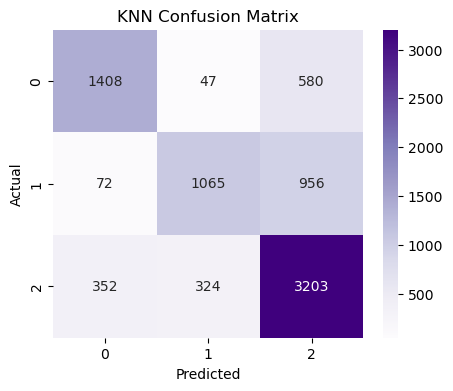

In [63]:
plt.figure(figsize=(5,4))
sns.heatmap(cm_knn, annot=True, fmt="d", cmap="Purples")
plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [64]:
print(classification_report(y_test, prediction))

              precision    recall  f1-score   support

        High       0.77      0.69      0.73      2035
         Low       0.74      0.51      0.60      2093
      Medium       0.68      0.83      0.74      3879

    accuracy                           0.71      8007
   macro avg       0.73      0.68      0.69      8007
weighted avg       0.72      0.71      0.70      8007



## Observation
KNN performed best with K = 9. It achieved high accuracy but detected very few fraud cases, giving a very low Recall and F1-Score.

<br><br><br><br>

# SVM

In [ ]:
from sklearn.svm import SVC

svm = SVC()

In [ ]:
svm.fit(X_train, y_train)

In [ ]:
y_pred_svm = svm.predict(X_test)
y_pred_svm

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm, average='weighted'))
print("Recall:", recall_score(y_test, y_pred_svm, average='weighted'))
print("F1:", f1_score(y_test, y_pred_svm, average='weighted'))

In [ ]:
cm_svm = confusion_matrix(y_test, y_pred_svm)
print(cm_svm)

In [ ]:
plt.figure(figsize=(5,4))
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Reds")
plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## Comparison Table
The performance of all four machine learning models was compared using Accuracy, Precision, Recall and F1-Score.

In [ ]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest", "KNN", "SVM"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_svm),
    ]
})

results

In [ ]:
plt.figure(figsize=(8,5))

colors = ['blue', 'green', 'orange', 'red', 'purple']

plt.bar(results["Model"], results["Accuracy"], color=colors)

plt.xticks(rotation=45)
plt.title("Model Accuracy Comparison")
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.show()

## Best Performing Model:
Random Forest is the most suitable model for predicting player engagement level in the given dataset, as it provides the most reliable and stable predictions compared to other tested models.

## Conclusion:

* Built and compared four classification models for fraud detection.
* Evaluated the models using Accuracy,Precision,Recall,F1-Score and Confusion Matrix.
* Decision Tree performed better for detecting fraud in comparison to other models.
* Accuracy alone was not enough because the dataset was imbalanced.

## Future Scope

* Improve the model by handling class imbalance using techniques like oversampling or undersampling.
* Test more machine learning models.
* Use a larger or updated dataset.
* Build a real-time fraud detection system.
